# Klasifikasi Kemiskinan Berdasarkan Indikator Sosial Ekonomi Kabupaten/Kota di Indonesia Menggunakan Algoritma *Random Forest*



**A. PREPROCESSING DATA**

Tujuan: memahami data awal, membersihkan baris yang benar-benar kosong, mengubah kolom numerik menjadi tipe angka, dan memeriksa kualitas data sebelum pemodelan.

**1. Import library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("default")
RANDOM_STATE = 42

print("Library berhasil diimpor.")

Library berhasil diimpor.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**2. Upload dan membaca dataset**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Klasifikasi Tingkat Kemiskinan di Indonesia (1).csv to Klasifikasi Tingkat Kemiskinan di Indonesia (1).csv


In [ ]:
# Mengambil nama file CSV yang diunggah agar tidak bergantung pada nama file yang persis sama.
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Tidak ada file CSV yang diunggah. Silakan unggah dataset CSV.")

file_path = csv_files[0]
df = pd.read_csv(file_path, sep=";")

print("File yang dibaca:", file_path)
print("Ukuran dataset awal:", df.shape)
display(df.head())

File yang dibaca: Klasifikasi Tingkat Kemiskinan di Indonesia (1).csv
Ukuran dataset awal: (999, 13)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Provinsi,Kab/Kota,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan
0,ACEH,Simeulue,"18,98","9,48",7148.0,"66,41","65,28","71,56","87,45","5,71","71,15",1648096.0,0.0
1,ACEH,Aceh Singkil,"20,36","8,68",8776.0,"69,22","67,43","69,56","78,58","8,36","62,85",1780419.0,1.0
2,ACEH,Aceh Selatan,"13,18","8,88",8180.0,"67,44","64,4","62,55","79,65","6,46","60,85",4345784.0,0.0
3,ACEH,Aceh Tenggara,"13,41","9,67",8030.0,"69,44","68,22","62,71","86,71","6,43","69,62",3487157.0,0.0
4,ACEH,Aceh Timur,"14,45","8,21",8577.0,"67,83","68,74","66,75","83,16","7,13","59,48",8433526.0,0.0


**3. Memahami dataset awal**

Bagian ini sengaja dilakukan sebelum konversi numerik. describe(include='all') membantu melihat gambaran awal setiap kolom, termasuk jumlah nilai, nilai unik, dan tipe data yang masih terbaca sebagai teks. Hasil ini dapat menjadi acuan saat menentukan kolom yang perlu dikonversi.

In [ ]:
print("Daftar kolom:")
for nomor, kolom in enumerate(df.columns, start=1):
    print(f"{nomor}. {kolom}")

print("\nInformasi tipe data awal:")
df.info()

Daftar kolom:
1. Provinsi
2. Kab/Kota
3. Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)
4. Rata-rata Lama Sekolah Penduduk 15+ (Tahun)
5. Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)
6. Indeks Pembangunan Manusia
7. Umur Harapan Hidup (Tahun)
8. Persentase rumah tangga yang memiliki akses terhadap sanitasi layak
9. Persentase rumah tangga yang memiliki akses terhadap air minum layak
10. Tingkat Pengangguran Terbuka
11. Tingkat Partisipasi Angkatan Kerja
12. PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)
13. Klasifikasi Kemiskinan

Informasi tipe data awal:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 13 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Provinsi                                                              514 non-null  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
print("Lima baris pertama:")
display(df.head())

print("Statistik deskriptif dataset awal:")
display(df.describe(include="all").T)

Lima baris pertama:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Provinsi,Kab/Kota,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan
0,ACEH,Simeulue,"18,98","9,48",7148.0,"66,41","65,28","71,56","87,45","5,71","71,15",1648096.0,0.0
1,ACEH,Aceh Singkil,"20,36","8,68",8776.0,"69,22","67,43","69,56","78,58","8,36","62,85",1780419.0,1.0
2,ACEH,Aceh Selatan,"13,18","8,88",8180.0,"67,44","64,4","62,55","79,65","6,46","60,85",4345784.0,0.0
3,ACEH,Aceh Tenggara,"13,41","9,67",8030.0,"69,44","68,22","62,71","86,71","6,43","69,62",3487157.0,0.0
4,ACEH,Aceh Timur,"14,45","8,21",8577.0,"67,83","68,74","66,75","83,16","7,13","59,48",8433526.0,0.0


Statistik deskriptif dataset awal:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Provinsi,514,34,JAWA TIMUR,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kab/Kota,514,514,Kota Jayapura,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),514,452,"5,93",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rata-rata Lama Sekolah Penduduk 15+ (Tahun),514,377,"8,03",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),514.0,NaN,NaN,NaN,10324.787938,2717.144186,3976.0,8574.0,10196.5,11719.0,23888.0
Indeks Pembangunan Manusia,514,452,"70,6",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Umur Harapan Hidup (Tahun),514,411,"71,6",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,514,487,"81,89",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Persentase rumah tangga yang memiliki akses terhadap air minum layak,514,465,"100,00",11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tingkat Pengangguran Terbuka,514,373,"5,86",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**4. Menghapus baris yang seluruh kolomnya kosong**

In [ ]:
jumlah_baris_awal = len(df)
jumlah_baris_kosong = df.isna().all(axis=1).sum()

print("Jumlah baris awal:", jumlah_baris_awal)
print("Jumlah baris yang seluruh kolomnya kosong:", jumlah_baris_kosong)

df = df.dropna(how="all").copy().reset_index(drop=True)

print("Ukuran setelah menghapus baris kosong:", df.shape)

Jumlah baris awal: 999
Jumlah baris yang seluruh kolomnya kosong: 485
Ukuran setelah menghapus baris kosong: (514, 13)


**5. Konversi kolom numerik**

Pada dataset, sebagian angka menggunakan koma sebagai tanda desimal. Kode berikut mengganti koma menjadi titik lalu mengonversi kolom menjadi numerik. errors='coerce' mengubah nilai yang tidak dapat dibaca sebagai angka menjadi NaN, sehingga hasil konversinya perlu diperiksa.

In [ ]:
kolom_numerik = [
    "Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)",
    "Rata-rata Lama Sekolah Penduduk 15+ (Tahun)",
    "Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)",
    "Indeks Pembangunan Manusia",
    "Umur Harapan Hidup (Tahun)",
    "Persentase rumah tangga yang memiliki akses terhadap sanitasi layak",
    "Persentase rumah tangga yang memiliki akses terhadap air minum layak",
    "Tingkat Pengangguran Terbuka",
    "Tingkat Partisipasi Angkatan Kerja",
    "PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)",
    "Klasifikasi Kemiskinan"
]

for kolom in kolom_numerik:
    df[kolom] = pd.to_numeric(
        df[kolom].astype(str).str.strip().str.replace(",", ".", regex=False),
        errors="coerce"
    )

print("Informasi dataset setelah konversi:")
df.info()

Informasi dataset setelah konversi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 514 entries, 0 to 513
Data columns (total 13 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Provinsi                                                              514 non-null    object 
 1   Kab/Kota                                                              514 non-null    object 
 2   Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)       514 non-null    float64
 3   Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                           514 non-null    float64
 4   Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)          514 non-null    float64
 5   Indeks Pembangunan Manusia                                            514 non-null    float64
 6   Umur Harapan Hidup (Tahun)                                    

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**6. Memeriksa missing value dan duplikasi**


In [ ]:
missing_df = pd.DataFrame({
    "Kolom": df.columns,
    "Jumlah Missing": df.isna().sum().values
})
display(missing_df)

print("Total missing value setelah konversi:", int(df.isna().sum().sum()))
print("Jumlah baris duplikat:", int(df.duplicated().sum()))

,Kolom,Jumlah Missing
0,Provinsi,0
1,Kab/Kota,0
2,Persentase Penduduk Miskin (P0) Menurut Kabupa...,0
3,Rata-rata Lama Sekolah Penduduk 15+ (Tahun),0
4,Pengeluaran per Kapita Disesuaikan (Ribu Rupia...,0
5,Indeks Pembangunan Manusia,0
6,Umur Harapan Hidup (Tahun),0
7,Persentase rumah tangga yang memiliki akses te...,0
8,Persentase rumah tangga yang memiliki akses te...,0
9,Tingkat Pengangguran Terbuka,0


Total missing value setelah konversi: 0
Jumlah baris duplikat: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
jumlah_sebelum_duplikat = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print("Jumlah baris sebelum menghapus duplikasi:", jumlah_sebelum_duplikat)
print("Jumlah baris setelah menghapus duplikasi:", len(df))

Jumlah baris sebelum menghapus duplikasi: 514
Jumlah baris setelah menghapus duplikasi: 514


**7. Statistik deskriptif setelah konversi**

Berbeda dari describe() awal, tabel ini menghitung statistik untuk kolom numerik yang sudah dikonversi. Gunakan nilai min, max, mean, dan standar deviasi untuk memahami skala serta rentang data.

In [ ]:
display(df[kolom_numerik].describe().T)

,count,mean,std,min,25%,50%,75%,max
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),514.0,1.227315e+01,7.458703e+00,2.38,7.150000e+00,10.455,1.488750e+01,4.166000e+01
Rata-rata Lama Sekolah Penduduk 15+ (Tahun),514.0,8.436615e+00,1.630842e+00,1.42,7.510000e+00,8.305,9.337500e+00,1.283000e+01
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),514.0,1.032479e+04,2.717144e+03,3976.00,8.574000e+03,10196.500,1.171900e+04,2.388800e+04
Indeks Pembangunan Manusia,514.0,6.992677e+01,6.497033e+00,32.84,6.664250e+01,69.610,7.311250e+01,8.718000e+01
Umur Harapan Hidup (Tahun),514.0,6.965681e+01,3.447464e+00,55.43,6.738750e+01,69.975,7.204250e+01,7.773000e+01
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,514.0,7.720224e+01,1.858355e+01,0.00,7.021750e+01,81.800,8.988250e+01,9.997000e+01
Persentase rumah tangga yang memiliki akses terhadap air minum layak,514.0,8.513661e+01,1.570166e+01,0.00,7.904250e+01,89.795,9.640000e+01,1.000000e+02
Tingkat Pengangguran Terbuka,514.0,5.059494e+00,2.636970e+00,0.00,3.180000e+00,4.565,6.530000e+00,1.337000e+01
Tingkat Partisipasi Angkatan Kerja,514.0,6.946446e+01,6.396405e+00,56.39,6.507000e+01,68.955,7.234250e+01,9.793000e+01
PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),514.0,2.196408e+07,4.790492e+07,147485.00,3.654292e+06,8814925.500,1.973510e+07,4.600810e+08


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**8. Distribusi target**

Periksa jumlah dan persentase setiap kelas. Jika salah satu kelas jauh lebih sedikit, dataset termasuk tidak seimbang (*imbalanced*).

Jumlah tiap kelas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Jumlah
Klasifikasi Kemiskinan,
0,452
1,62



Persentase tiap kelas:


,Persentase (%)
Klasifikasi Kemiskinan,
0,87.94
1,12.06


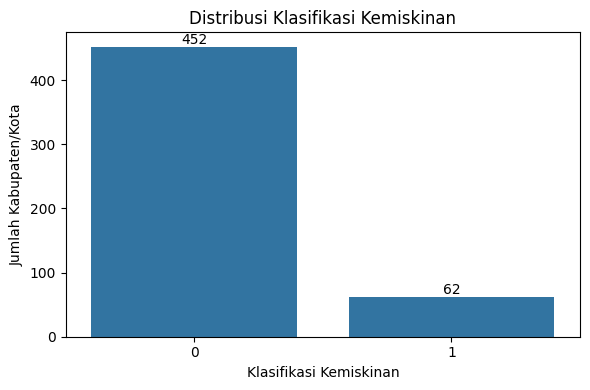

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
target_asli = "Klasifikasi Kemiskinan"
df[target_asli] = df[target_asli].astype(int)

print("Jumlah tiap kelas:")
display(df[target_asli].value_counts(dropna=False).sort_index().rename("Jumlah"))

print("\nPersentase tiap kelas:")
display(
    (df[target_asli].value_counts(normalize=True, dropna=False)
     .sort_index().mul(100).round(2).rename("Persentase (%)"))
)

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=target_asli, data=df)
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.title("Distribusi Klasifikasi Kemiskinan")
plt.xlabel("Klasifikasi Kemiskinan")
plt.ylabel("Jumlah Kabupaten/Kota")
plt.tight_layout()
plt.show()

**9. Heatmap korelasi**

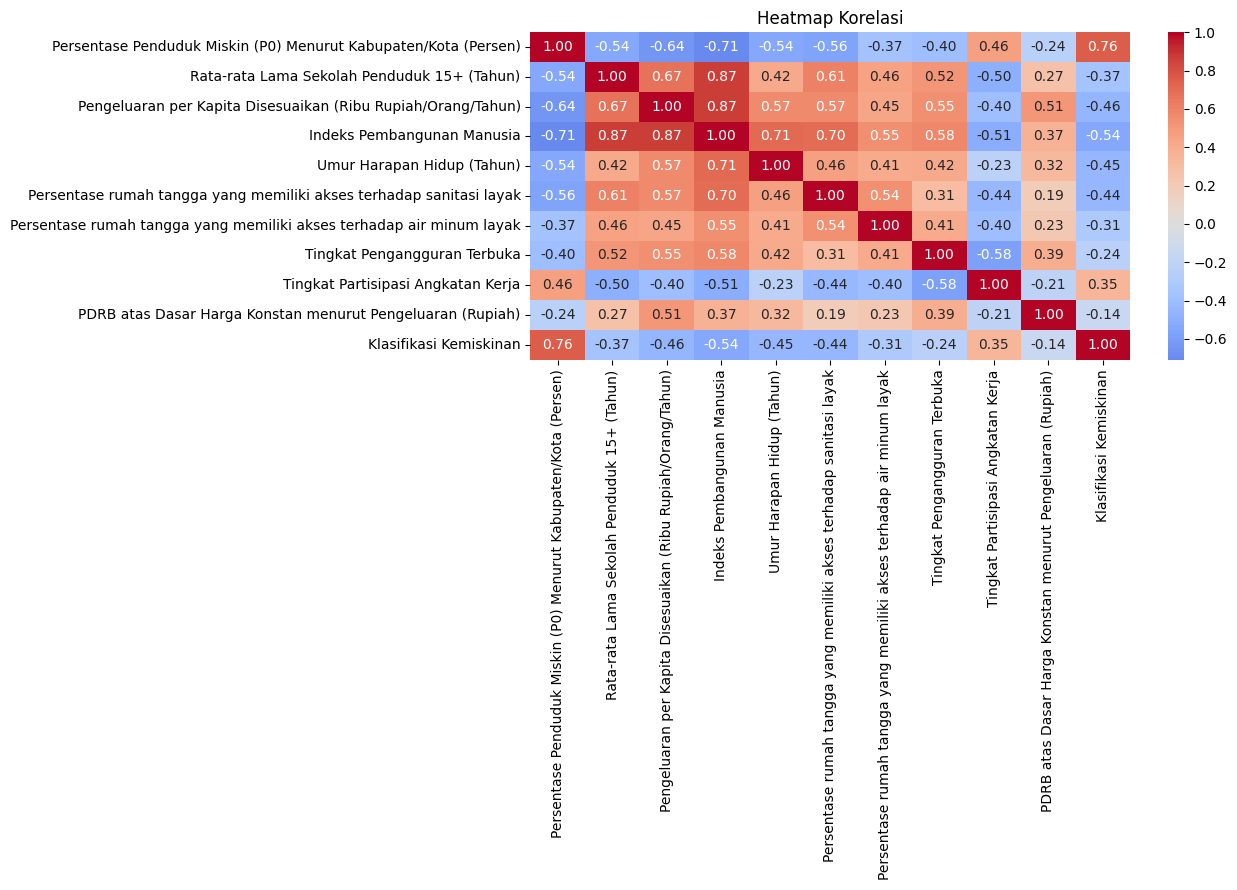

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
kolom_heatmap = [
    "Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)",
    "Rata-rata Lama Sekolah Penduduk 15+ (Tahun)",
    "Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)",
    "Indeks Pembangunan Manusia",
    "Umur Harapan Hidup (Tahun)",
    "Persentase rumah tangga yang memiliki akses terhadap sanitasi layak",
    "Persentase rumah tangga yang memiliki akses terhadap air minum layak",
    "Tingkat Pengangguran Terbuka",
    "Tingkat Partisipasi Angkatan Kerja",
    "PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)",
    "Klasifikasi Kemiskinan"
]

data_heatmap = df[kolom_heatmap].dropna()

plt.figure(figsize=(13, 9))
sns.heatmap(
    data_heatmap.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Heatmap Korelasi")
plt.tight_layout()
plt.show()

**10. Menyiapkan dataset model-ready dan mengeluarkan P0**

Setelah heatmap ditinjau, **P0** tidak dimasukkan ke fitur model. **Provinsi dan Kab/Kota** juga tidak digunakan sebagai fitur karena keduanya merupakan identitas wilayah, bukan indikator numerik sosial ekonomi dalam rancangan model ini.

Target tetap Klasifikasi_Kemiskinan. Sembilan fitur yang digunakan adalah RLS, Pengeluaran per Kapita, IPM, UHH, Sanitasi Layak, Air Minum Layak, TPT, TPAK, dan PDRB.

In [ ]:
rename_cols = {
    "Rata-rata Lama Sekolah Penduduk 15+ (Tahun)": "RLS",
    "Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)": "Pengeluaran_per_Kapita",
    "Indeks Pembangunan Manusia": "IPM",
    "Umur Harapan Hidup (Tahun)": "UHH",
    "Persentase rumah tangga yang memiliki akses terhadap sanitasi layak": "Sanitasi_Layak",
    "Persentase rumah tangga yang memiliki akses terhadap air minum layak": "Air_Minum_Layak",
    "Tingkat Pengangguran Terbuka": "TPT",
    "Tingkat Partisipasi Angkatan Kerja": "TPAK",
    "PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)": "PDRB",
    "Klasifikasi Kemiskinan": "Klasifikasi_Kemiskinan"
}

feature_cols = [
    "RLS",
    "Pengeluaran_per_Kapita",
    "IPM",
    "UHH",
    "Sanitasi_Layak",
    "Air_Minum_Layak",
    "TPT",
    "TPAK",
    "PDRB"
]
target_col = "Klasifikasi_Kemiskinan"

kolom_model_asli = [
    "Rata-rata Lama Sekolah Penduduk 15+ (Tahun)",
    "Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)",
    "Indeks Pembangunan Manusia",
    "Umur Harapan Hidup (Tahun)",
    "Persentase rumah tangga yang memiliki akses terhadap sanitasi layak",
    "Persentase rumah tangga yang memiliki akses terhadap air minum layak",
    "Tingkat Pengangguran Terbuka",
    "Tingkat Partisipasi Angkatan Kerja",
    "PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)",
    "Klasifikasi Kemiskinan"
]

model_df = (
    df[kolom_model_asli]
    .dropna()
    .rename(columns=rename_cols)
    .reset_index(drop=True)
)

if not set(model_df[target_col].dropna().unique()).issubset({0, 1}):
    raise ValueError("Target harus berisi label 0 dan/atau 1. Periksa kembali kolom target.")

model_df[target_col] = model_df[target_col].astype(int)

print("Ukuran dataset model-ready:", model_df.shape)
print("Jumlah fitur:", len(feature_cols))
print("Fitur yang digunakan:", feature_cols)
print("Target:", target_col)
print("Jumlah baris yang dikeluarkan karena missing pada kolom model:",
      len(df) - len(model_df))

display(model_df.head())
model_df.info()

Ukuran dataset model-ready: (514, 10)
Jumlah fitur: 9
Fitur yang digunakan: ['RLS', 'Pengeluaran_per_Kapita', 'IPM', 'UHH', 'Sanitasi_Layak', 'Air_Minum_Layak', 'TPT', 'TPAK', 'PDRB']
Target: Klasifikasi_Kemiskinan
Jumlah baris yang dikeluarkan karena missing pada kolom model: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,RLS,Pengeluaran_per_Kapita,IPM,UHH,Sanitasi_Layak,Air_Minum_Layak,TPT,TPAK,PDRB,Klasifikasi_Kemiskinan
0,9.48,7148.0,66.41,65.28,71.56,87.45,5.71,71.15,1648096.0,0
1,8.68,8776.0,69.22,67.43,69.56,78.58,8.36,62.85,1780419.0,1
2,8.88,8180.0,67.44,64.40,62.55,79.65,6.46,60.85,4345784.0,0
3,9.67,8030.0,69.44,68.22,62.71,86.71,6.43,69.62,3487157.0,0
4,8.21,8577.0,67.83,68.74,66.75,83.16,7.13,59.48,8433526.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 514 entries, 0 to 513
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   RLS                     514 non-null    float64
 1   Pengeluaran_per_Kapita  514 non-null    float64
 2   IPM                     514 non-null    float64
 3   UHH                     514 non-null    float64
 4   Sanitasi_Layak          514 non-null    float64
 5   Air_Minum_Layak         514 non-null    float64
 6   TPT                     514 non-null    float64
 7   TPAK                    514 non-null    float64
 8   PDRB                    514 non-null    float64
 9   Klasifikasi_Kemiskinan  514 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 40.3 KB


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**11. Statistik deskriptif dataset model-ready**

Tabel ini menjadi ringkasan statistik akhir untuk fitur yang benar-benar akan masuk ke model. P0 tidak ada pada tabel ini karena sudah dikeluarkan dari dataset model-ready.

In [ ]:
display(model_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
RLS,514.0,8.436615e+00,1.630842e+00,1.42,7.510000e+00,8.305,9.337500e+00,1.283000e+01
Pengeluaran_per_Kapita,514.0,1.032479e+04,2.717144e+03,3976.00,8.574000e+03,10196.500,1.171900e+04,2.388800e+04
IPM,514.0,6.992677e+01,6.497033e+00,32.84,6.664250e+01,69.610,7.311250e+01,8.718000e+01
UHH,514.0,6.965681e+01,3.447464e+00,55.43,6.738750e+01,69.975,7.204250e+01,7.773000e+01
Sanitasi_Layak,514.0,7.720224e+01,1.858355e+01,0.00,7.021750e+01,81.800,8.988250e+01,9.997000e+01
Air_Minum_Layak,514.0,8.513661e+01,1.570166e+01,0.00,7.904250e+01,89.795,9.640000e+01,1.000000e+02
TPT,514.0,5.059494e+00,2.636970e+00,0.00,3.180000e+00,4.565,6.530000e+00,1.337000e+01
TPAK,514.0,6.946446e+01,6.396405e+00,56.39,6.507000e+01,68.955,7.234250e+01,9.793000e+01
PDRB,514.0,2.196408e+07,4.790492e+07,147485.00,3.654292e+06,8814925.500,1.973510e+07,4.600810e+08
Klasifikasi_Kemiskinan,514.0,1.206226e-01,3.260054e-01,0.00,0.000000e+00,0.000,0.000000e+00,1.000000e+00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**B. TRAINING / PEMBENTUKAN MODEL**

**12. Menentukan fitur dan target**

In [ ]:
X = model_df[feature_cols].copy()
y = model_df[target_col].copy()

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)
print("\nDistribusi target:")
print(y.value_counts().sort_index())

Ukuran X: (514, 9)
Ukuran y: (514,)

Distribusi target:
Klasifikasi_Kemiskinan
0    452
1     62
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**13. Train-test split**

Data dibagi menjadi **80%** training dan **20%** testing. `stratify=y` menjaga proporsi kelas 0 dan 1 tetap relatif serupa pada kedua bagian. `random_state=42` membuat pembagian dapat direproduksi.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])

print("\nDistribusi target training:")
print(y_train.value_counts().sort_index())

print("\nDistribusi target testing:")
print(y_test.value_counts().sort_index())

Jumlah data training: 411
Jumlah data testing : 103

Distribusi target training:
Klasifikasi_Kemiskinan
0    361
1     50
Name: count, dtype: int64

Distribusi target testing:
Klasifikasi_Kemiskinan
0    91
1    12
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**14. Random Forest baseline**

In [ ]:
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)
print("Random Forest baseline berhasil dilatih.")

Random Forest baseline berhasil dilatih.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**15. Stratified 5-Fold Cross-Validation untuk baseline**

Cross-validation dilakukan hanya pada data training. Setiap putaran menggunakan empat fold untuk melatih model dan satu fold untuk validasi; proses bergantian sebanyak lima kali. Hasil di bawah adalah rata-rata lima putaran, bukan hasil pada data testing.

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_result = cross_validate(
    rf_baseline,
    X_train,
    y_train,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"],
    n_jobs=1
)

hasil_cv = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision kelas 1", "Recall kelas 1", "F1-Score kelas 1"],
    "Rata-rata 5-fold": [
        cv_result["test_accuracy"].mean(),
        cv_result["test_precision"].mean(),
        cv_result["test_recall"].mean(),
        cv_result["test_f1"].mean()
    ],
    "Standar deviasi": [
        cv_result["test_accuracy"].std(),
        cv_result["test_precision"].std(),
        cv_result["test_recall"].std(),
        cv_result["test_f1"].std()
    ]
})
display(hasil_cv)

,Metrik,Rata-rata 5-fold,Standar deviasi
0,Accuracy,0.914752,0.023325
1,Precision kelas 1,0.735952,0.125276
2,Recall kelas 1,0.460000,0.135647
3,F1-Score kelas 1,0.561340,0.131110


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**16. Hyperparameter tuning**

`GridSearchCV` mencoba kombinasi parameter yang ditentukan, lalu menilai setiap kombinasi menggunakan Stratified 5-Fold Cross-Validation pada data training. Dengan grid ini terdapat 36 kombinasi dan 180 proses pelatihan/validasi (36 × 5).

`scoring="f1"` memilih model berdasarkan F1 untuk kelas positif 1. Ini sesuai bila kelas 1 adalah kelas yang ingin diperhatikan, tetapi makna kelas 1 harus dipastikan dari definisi target dataset.

In [ ]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=1
    ),
    param_grid=param_grid,
    cv=skf,
    scoring="f1",
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Parameter terbaik:")
print(grid_search.best_params_)
print("\nBest mean CV F1-score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Parameter terbaik:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best mean CV F1-score: 0.6106


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**17. Menetapkan model final**

Model final berasal dari kombinasi parameter terbaik yang ditemukan `GridSearchCV`. Model ini sudah di-fit ulang pada seluruh data training oleh `GridSearchCV (refit=True)` dan akan dipakai untuk evaluasi pada data testing.

In [ ]:
rf_final = grid_search.best_estimator_
rf_final.set_params(n_jobs=-1)

print("Model final:")
print(rf_final)

Model final:
RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_split=5, n_jobs=-1, random_state=42)


**C.EVALUASI MODEL FINAL**

**18. Prediksi pada data testing**

Data testing disimpan terpisah selama pemilihan parameter. Model final baru digunakan di sini untuk memprediksi data testing.

In [ ]:
y_pred = rf_final.predict(X_test)

print("Prediksi berhasil dilakukan.")
print("Jumlah data yang diprediksi:", len(y_pred))

Prediksi berhasil dilakukan.
Jumlah data yang diprediksi: 103


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**19. Accuracy, Precision, Recall, dan F1-Score**

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

hasil_evaluasi = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision kelas 1", "Recall kelas 1", "F1-Score kelas 1"],
    "Nilai": [accuracy, precision, recall, f1]
})
display(hasil_evaluasi.style.format({"Nilai": "{:.4f}"}))

,Metrik,Nilai
0,Accuracy,0.9515
1,Precision kelas 1,0.7692
2,Recall kelas 1,0.8333
3,F1-Score kelas 1,0.8000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**20. Classification report**

In [ ]:
print("=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Kelas 0", "Kelas 1"],
        zero_division=0
    )
)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Kelas 0       0.98      0.97      0.97        91
     Kelas 1       0.77      0.83      0.80        12

    accuracy                           0.95       103
   macro avg       0.87      0.90      0.89       103
weighted avg       0.95      0.95      0.95       103



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**21. Confusion matrix**

Baris menunjukkan kelas aktual, sedangkan kolom menunjukkan kelas prediksi. Matriks ini membantu melihat jumlah prediksi benar dan salah pada masing-masing kelas.

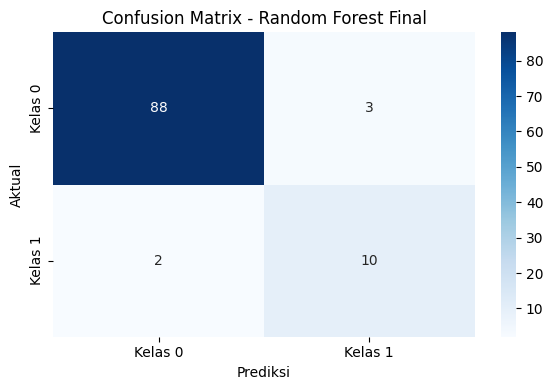

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Kelas 0", "Kelas 1"],
    yticklabels=["Kelas 0", "Kelas 1"]
)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix - Random Forest Final")
plt.tight_layout()
plt.show()

**22. Feature importance**

Feature importance memperlihatkan seberapa besar kontribusi relatif fitur dalam pembentukan keputusan pohon-pohon Random Forest. Ini bukan bukti bahwa fitur tersebut menyebabkan kemiskinan; fitur yang saling berkorelasi juga dapat berbagi atau mengubah nilai importance.

,Fitur,Importance
0,IPM,0.242429
1,Pengeluaran_per_Kapita,0.238810
2,UHH,0.180786
3,PDRB,0.086015
4,RLS,0.062367
5,Sanitasi_Layak,0.056713
6,TPT,0.054590
7,Air_Minum_Layak,0.039770
8,TPAK,0.038521


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


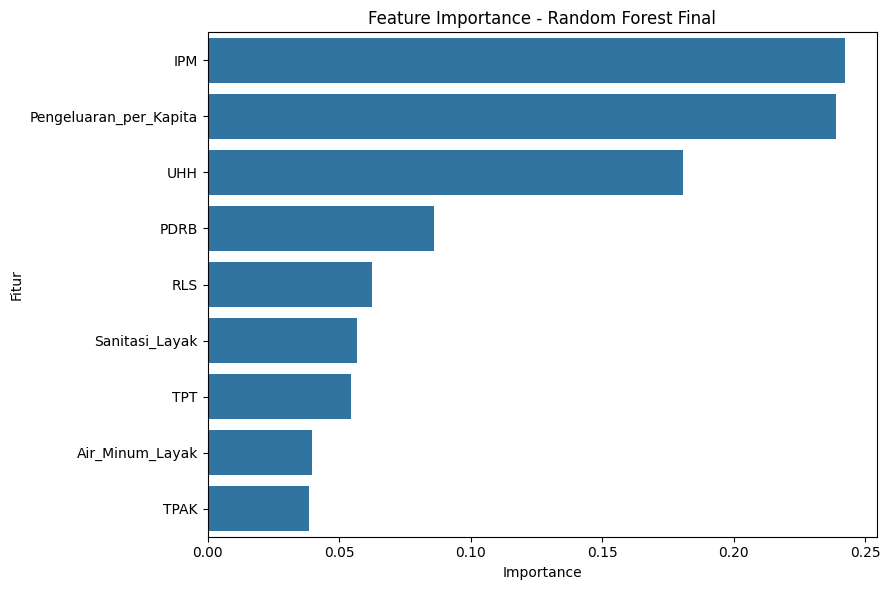

In [ ]:
feature_importance = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": rf_final.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

display(feature_importance)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Fitur"
)
plt.title("Feature Importance - Random Forest Final")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

**23. Pemeriksaan sederhana indikasi overfitting**

Perbandingan accuracy training dan testing dapat memberi petunjuk awal, tetapi tidak cukup untuk membuktikan ada atau tidaknya overfitting. Pertimbangkan juga hasil cross-validation dan metrik untuk kelas 1.

In [ ]:
y_train_pred = rf_final.predict(X_train)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

display(pd.DataFrame({
    "Data": ["Training", "Testing"],
    "Accuracy": [train_accuracy, test_accuracy]
}).style.format({"Accuracy": "{:.4f}"}))

,Data,Accuracy
0,Training,0.9951
1,Testing,0.9515


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**E. INFERENCE (PREDIKSI DATA BARU)**

Inference menggunakan model final dan sembilan fitur yang sama persis seperti saat training. Masukkan nilai dengan satuan yang sesuai dataset. Probabilitas keluaran model adalah skor probabilitas model, bukan jaminan kepastian kondisi nyata.

In [ ]:
print("=" * 65)
print("INFERENCE RANDOM FOREST")
print("=" * 65)

print("\nRentang nilai fitur pada dataset model:")
for kolom in feature_cols:
    print(f"{kolom:25s}: {X[kolom].min():,.2f} - {X[kolom].max():,.2f}")

print("\nMasukkan data baru sesuai satuan dataset.")
rls = float(input("1. RLS (tahun): "))
pengeluaran = float(input("2. Pengeluaran per Kapita (ribu rupiah/orang/tahun): "))
ipm = float(input("3. IPM: "))
uhh = float(input("4. UHH (tahun): "))
sanitasi = float(input("5. Sanitasi Layak (%): "))
air_minum = float(input("6. Air Minum Layak (%): "))
tpt = float(input("7. TPT (%): "))
tpak = float(input("8. TPAK (%): "))
pdrb = float(input("9. PDRB (ikuti satuan pada dataset): "))

data_baru = pd.DataFrame([{
    "RLS": rls,
    "Pengeluaran_per_Kapita": pengeluaran,
    "IPM": ipm,
    "UHH": uhh,
    "Sanitasi_Layak": sanitasi,
    "Air_Minum_Layak": air_minum,
    "TPT": tpt,
    "TPAK": tpak,
    "PDRB": pdrb
}])

# Memeriksa apakah ada input di luar rentang yang pernah dilihat model.
peringatan_rentang = []
for kolom in feature_cols:
    nilai = data_baru.loc[0, kolom]
    nilai_min = X_train[kolom].min()
    nilai_max = X_train[kolom].max()
    if nilai < nilai_min or nilai > nilai_max:
        peringatan_rentang.append(
            f"{kolom}: {nilai:,.2f} (rentang training {nilai_min:,.2f}–{nilai_max:,.2f})"
        )

if peringatan_rentang:
    print("\nPERINGATAN: ada input di luar rentang data training:")
    for pesan in peringatan_rentang:
        print("-", pesan)
    print("Prediksi tetap dapat dihitung, tetapi hasil perlu ditafsirkan dengan hati-hati.")
else:
    print("\nSemua input berada dalam rentang data training.")

display(data_baru)

prediksi = int(rf_final.predict(data_baru)[0])
probabilitas = rf_final.predict_proba(data_baru)[0]
kelas_model = list(rf_final.classes_)
probabilitas_per_kelas = dict(zip(kelas_model, probabilitas))

print("\n" + "=" * 65)
print("HASIL INFERENCE")
print("=" * 65)
print("Prediksi kelas:", prediksi)
print("Catatan: arti substantif Kelas 0 dan Kelas 1 mengikuti definisi label dataset.")

for kelas in kelas_model:
    print(f"Probabilitas Kelas {kelas}: {probabilitas_per_kelas[kelas]:.2%}")
print("=" * 65)


INFERENCE RANDOM FOREST

Rentang nilai fitur pada dataset model:
RLS                      : 1.42 - 12.83
Pengeluaran_per_Kapita   : 3,976.00 - 23,888.00
IPM                      : 32.84 - 87.18
UHH                      : 55.43 - 77.73
Sanitasi_Layak           : 0.00 - 99.97
Air_Minum_Layak          : 0.00 - 100.00
TPT                      : 0.00 - 13.37
TPAK                     : 56.39 - 97.93
PDRB                     : 147,485.00 - 460,081,046.00

Masukkan data baru sesuai satuan dataset.
1. RLS (tahun): 9
2. Pengeluaran per Kapita (ribu rupiah/orang/tahun): 4000
3. IPM: 32000
4. UHH (tahun): 70
5. Sanitasi Layak (%): 80
6. Air Minum Layak (%): 80
7. TPT (%): 9
8. TPAK (%): 80
9. PDRB (ikuti satuan pada dataset): 400.000

PERINGATAN: ada input di luar rentang data training:
- IPM: 32,000.00 (rentang training 32.84–87.18)
- PDRB: 400.00 (rentang training 467,690.00–460,081,046.00)
Prediksi tetap dapat dihitung, tetapi hasil perlu ditafsirkan dengan hati-hati.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,RLS,Pengeluaran_per_Kapita,IPM,UHH,Sanitasi_Layak,Air_Minum_Layak,TPT,TPAK,PDRB
0,9.0,4000.0,32000.0,70.0,80.0,80.0,9.0,80.0,400.0



HASIL INFERENCE
Prediksi kelas: 0
Catatan: arti substantif Kelas 0 dan Kelas 1 mengikuti definisi label dataset.
Probabilitas Kelas 0: 74.38%
Probabilitas Kelas 1: 25.62%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**F. RINGKASAN HASIL**

Jalankan cell ini setelah semua tahapan selesai. Nilai akan diambil dari hasil eksekusi notebook saat itu, bukan dari hasil eksekusi lama.

In [ ]:
print("=" * 60)
print("RINGKASAN HASIL RANDOM FOREST")
print("=" * 60)
print("Jumlah data model-ready :", len(model_df))
print("Data training           :", len(X_train))
print("Data testing            :", len(X_test))
print("\nParameter terbaik:")
print(grid_search.best_params_)
print("Best mean CV F1-score   :", f"{grid_search.best_score_:.4f}")
print("\nHasil evaluasi data testing:")
print(f"Accuracy               : {accuracy:.4f}")
print(f"Precision kelas 1      : {precision:.4f}")
print(f"Recall kelas 1         : {recall:.4f}")
print(f"F1-Score kelas 1       : {f1:.4f}")
print("\nTiga fitur dengan importance tertinggi:")
display(feature_importance.head(3))

RINGKASAN HASIL RANDOM FOREST
Jumlah data model-ready : 514
Data training           : 411
Data testing            : 103

Parameter terbaik:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best mean CV F1-score   : 0.6106

Hasil evaluasi data testing:
Accuracy               : 0.9515
Precision kelas 1      : 0.7692
Recall kelas 1         : 0.8333
F1-Score kelas 1       : 0.8000

Tiga fitur dengan importance tertinggi:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Fitur,Importance
0,IPM,0.242429
1,Pengeluaran_per_Kapita,0.238810
2,UHH,0.180786
